**Upload my Excel dataset**

In [1]:
from google.colab import files

uploaded = files.upload()

Saving ApexPlanet_DataAnalytics_Dataset.xlsx to ApexPlanet_DataAnalytics_Dataset.xlsx


**Import libraries and load the dataset**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the uploaded Excel file
file_name = next(iter(uploaded))
df = pd.read_excel(file_name)

# Display a confirmation
print("Dataset loaded successfully!")
print("File name:", file_name)

Dataset loaded successfully!
File name: ApexPlanet_DataAnalytics_Dataset.xlsx


**Inspect the dataset**

In [3]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# First five rows
display(df.head())

# Column names
print("Column Names:")
print(df.columns.tolist())

# Data types and non-empty values
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Missing-value percentages
print("\nMissing Value Percentages:")
print((df.isnull().mean() * 100).round(2))

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical summary
display(df.describe(include="all").T)

Dataset Shape: (1000, 12)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


Column Names:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   object 
 6   City           987 non-null    object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 93.9+ KB

Missing Values:
Order_ID      

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,1000,992,ORD100050,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,1000,342,2025-04-16,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,1000,947,CUST2515,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,1000,425,Customer_359,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,980.0,NaN,NaN,NaN,41.360204,13.822597,18.0,30.0,41.0,54.0,65.0
Gender,1000,2,Male,511,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,987,8,Patna,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1000,6,Mobile,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,1000,5,Electronics,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1000.0,NaN,NaN,NaN,5.435,2.838632,1.0,3.0,5.0,8.0,10.0


**Univariate analysis**

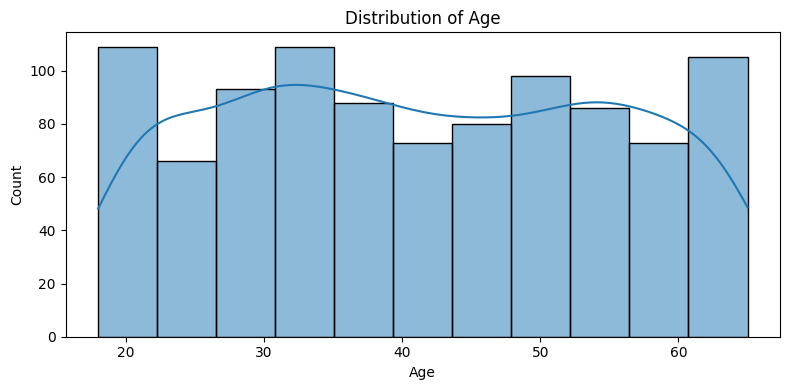

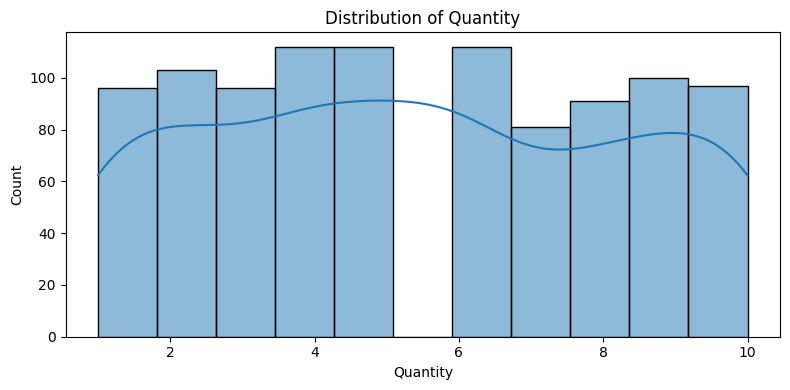

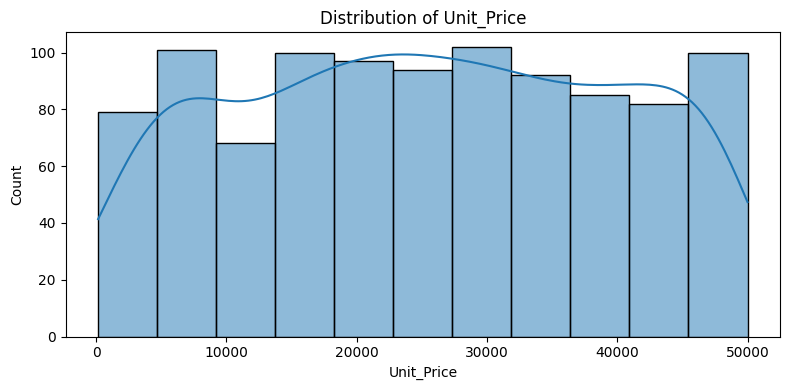

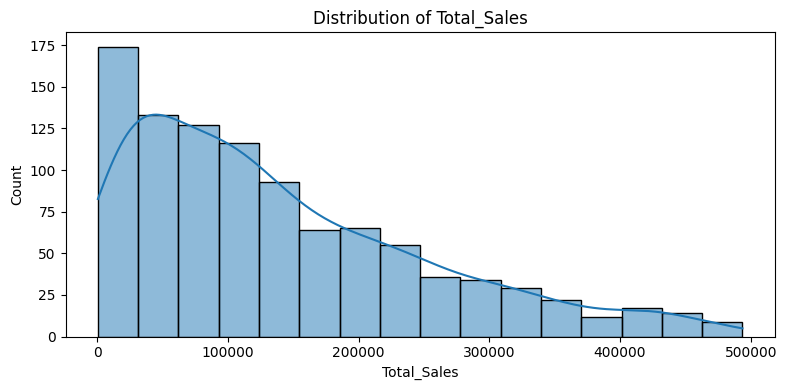

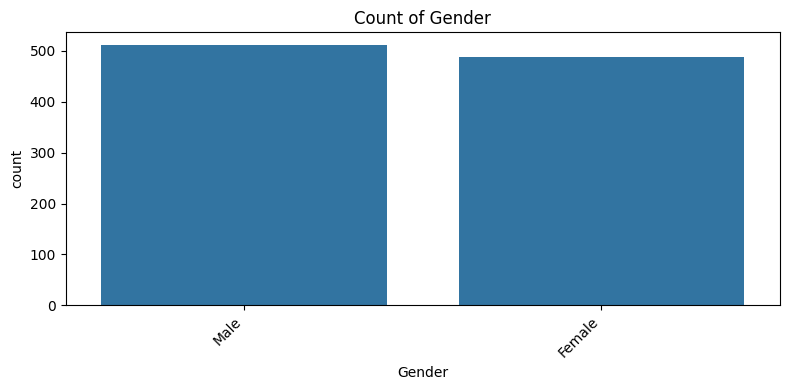

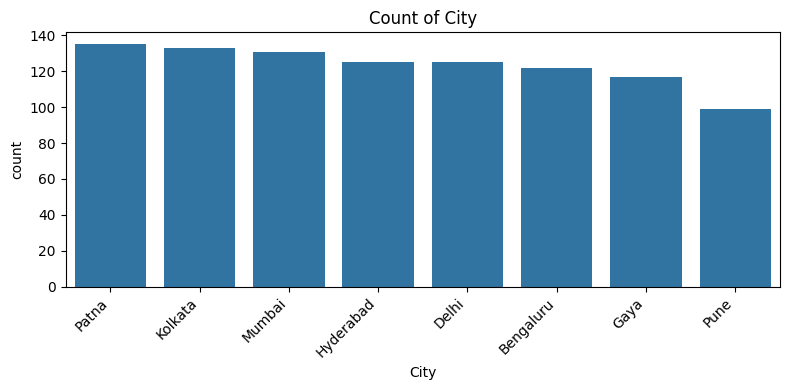

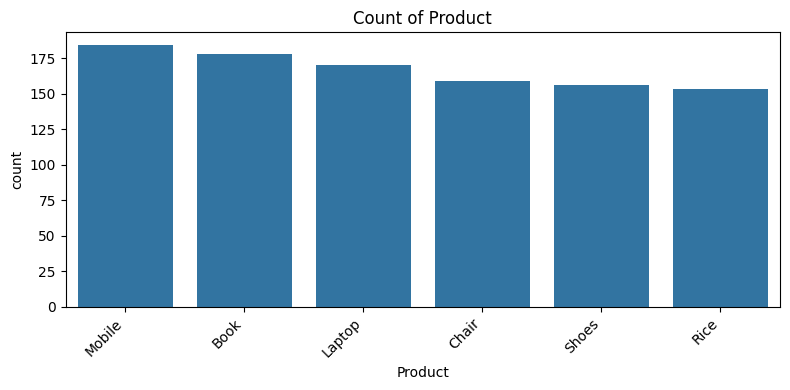

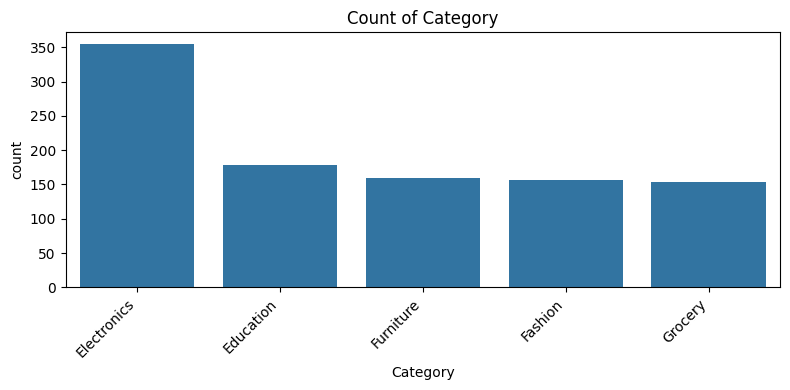

In [4]:
# Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

# Histograms for numerical columns
for col in numerical_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

# Count plots for categorical columns
for col in categorical_cols:
    if df[col].nunique() <= 20:
        plt.figure(figsize=(8, 4))
        order = df[col].value_counts().index
        sns.countplot(data=df, x=col, order=order)
        plt.title(f"Count of {col}")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

**Bivariate analysis**

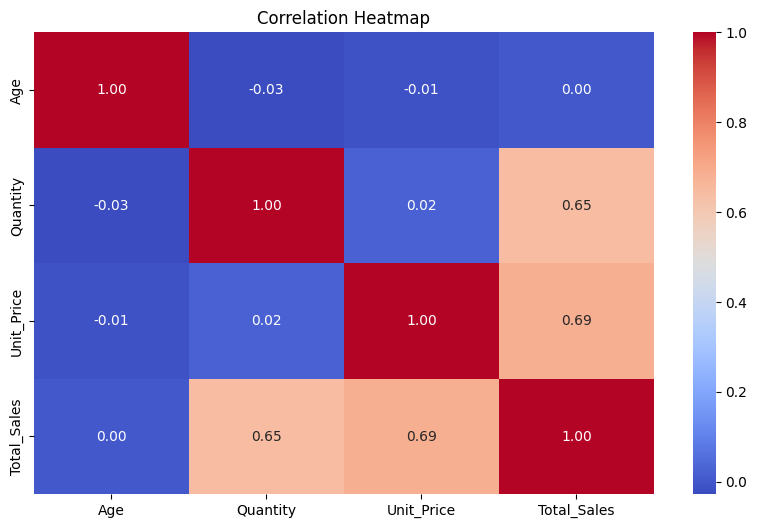

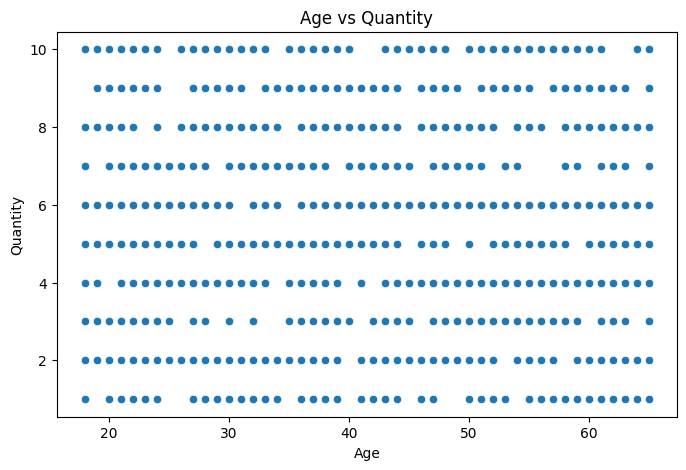

In [5]:
# Correlation heatmap
numerical_cols = df.select_dtypes(include=np.number).columns

if len(numerical_cols) >= 2:
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        df[numerical_cols].corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Correlation Heatmap")
    plt.show()

# Scatter plot for the first two numerical columns
if len(numerical_cols) >= 2:
    x_col = numerical_cols[0]
    y_col = numerical_cols[1]

    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x=x_col, y=y_col)
    plt.title(f"{x_col} vs {y_col}")
    plt.show()

# Box plot comparing a numerical variable across categories
if len(categorical_cols) > 0 and len(numerical_cols) > 0:
    cat_col = categorical_cols[0]
    num_col = numerical_cols[0]

    if df[cat_col].nunique() <= 15:
        plt.figure(figsize=(10, 5))
        sns.boxplot(data=df, x=cat_col, y=num_col)
        plt.xticks(rotation=45, ha="right")
        plt.title(f"{num_col} by {cat_col}")
        plt.show()

**Outlier detection**

,Column,Lower Limit,Upper Limit,Outlier Count
0,Age,-6.0000,90.0000,0
1,Quantity,-4.5000,15.5000,0
2,Unit_Price,-21529.2675,72937.3725,0
3,Total_Sales,-187917.7425,438707.2575,19


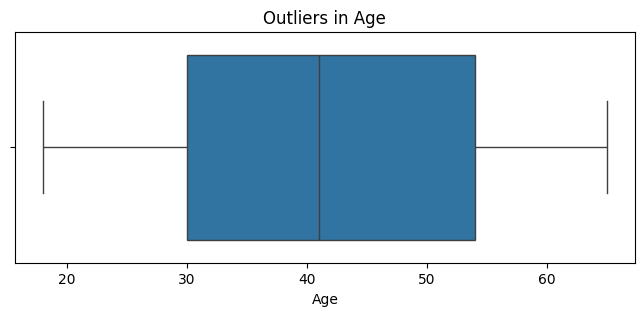

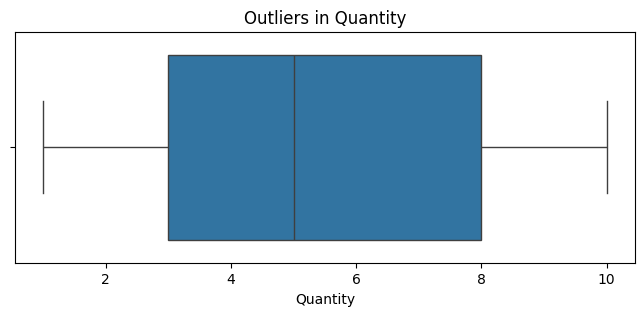

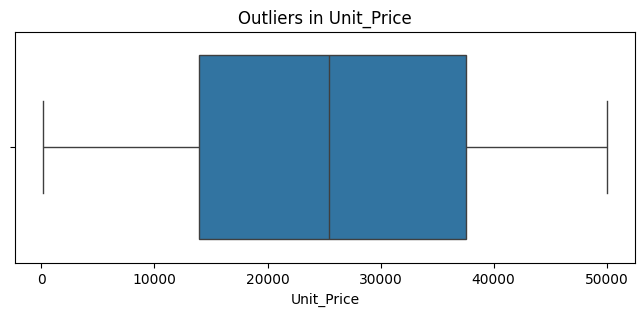

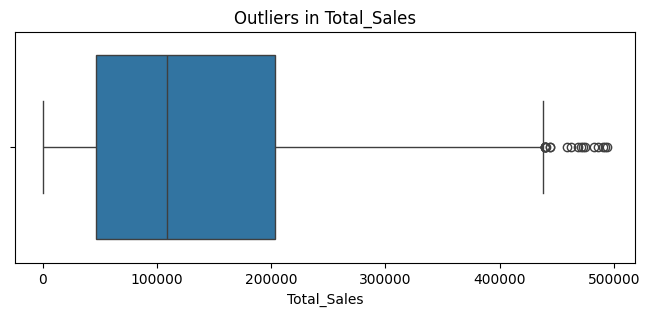

In [6]:
# Outlier detection using IQR
numerical_cols = df.select_dtypes(include=np.number).columns

outlier_summary = []

for col in numerical_cols:
    values = df[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (values < lower_limit) | (values > upper_limit)
    ).sum()

    outlier_summary.append({
        "Column": col,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": outlier_count
    })

display(pd.DataFrame(outlier_summary))

# Box plots
for col in numerical_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Outliers in {col}")
    plt.show()

**Multivariate analysis**

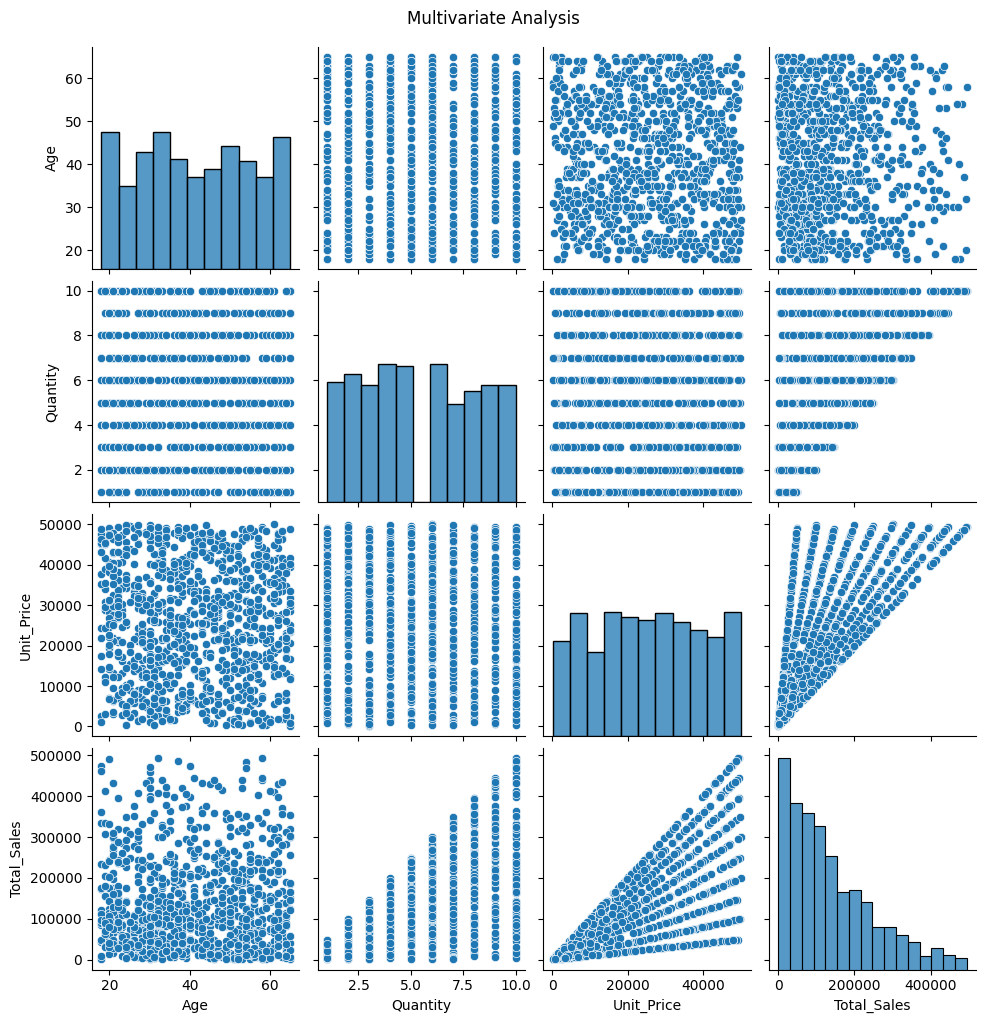

Strongly correlated pairs:


""


In [7]:
# Select up to four numerical columns
selected_cols = list(numerical_cols[:4])

if len(selected_cols) >= 2:
    # Use a sample for faster plotting on large datasets
    sample_df = df[selected_cols].dropna()

    if len(sample_df) > 1000:
        sample_df = sample_df.sample(
            n=1000, random_state=42
        )

    sns.pairplot(sample_df)
    plt.suptitle("Multivariate Analysis", y=1.02)
    plt.show()

# Display strong correlations
if len(numerical_cols) >= 2:
    correlation = df[numerical_cols].corr()

    strong_pairs = []

    for i in range(len(correlation.columns)):
        for j in range(i + 1, len(correlation.columns)):
            value = correlation.iloc[i, j]

            if pd.notna(value) and abs(value) >= 0.7:
                strong_pairs.append({
                    "Variable 1": correlation.columns[i],
                    "Variable 2": correlation.columns[j],
                    "Correlation": round(value, 2)
                })

    print("Strongly correlated pairs:")
    display(pd.DataFrame(strong_pairs))

**Business-focused visualizations**

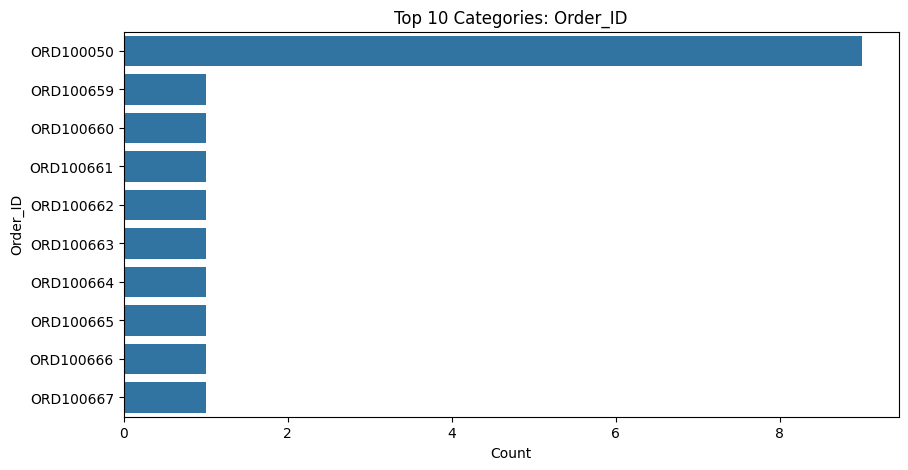

In [8]:
# Top 10 categories
if len(categorical_cols) > 0:
    col = categorical_cols[0]
    top_categories = df[col].value_counts().head(10)

    plt.figure(figsize=(10, 5))
    sns.barplot(x=top_categories.values, y=top_categories.index)
    plt.title(f"Top 10 Categories: {col}")
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.show()

# Average numerical value by category
if len(categorical_cols) > 0 and len(numerical_cols) > 0:
    cat_col = categorical_cols[0]
    num_col = numerical_cols[0]

    if df[cat_col].nunique() <= 20:
        grouped = (
            df.groupby(cat_col, observed=True)[num_col]
            .mean()
            .sort_values(ascending=False)
        )

        display(grouped.rename("Average").to_frame())

        plt.figure(figsize=(10, 5))
        sns.barplot(x=grouped.index, y=grouped.values)
        plt.title(f"Average {num_col} by {cat_col}")
        plt.xticks(rotation=45, ha="right")
        plt.show()

**Save my analysis outputs**

In [9]:
# Save dataset information
dataset_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isnull().sum().values,
    "Missing Percentage": (
        df.isnull().mean().mul(100).round(2).values
    ),
    "Unique Values": df.nunique().values
})

dataset_summary.to_csv(
    "dataset_summary.csv", index=False
)

# Save a correlation matrix
if len(numerical_cols) >= 2:
    df[numerical_cols].corr().to_csv(
        "correlation_matrix.csv"
    )

print("Analysis files saved successfully!")

Analysis files saved successfully!


In [10]:
from google.colab import files

files.download("dataset_summary.csv")

if len(numerical_cols) >= 2:
    files.download("correlation_matrix.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>